# Sensitivity analysis and KPI error bars

Two questions about a CO₂ VSA cycle (the shipped deck `Perez2019_A`, four steps on 13X):

1. **Which uncertain inputs move purity and recovery?** Morris screening varies the inputs one at a time along random trajectories through their ranges, so every input is tested at many different settings of the others. Cost: trajectories × (inputs + 1) runs.
2. **How uncertain are purity and recovery?** Monte Carlo propagation with Latin hypercube sampling varies the inputs that matter all together; the 5th–95th percentile band of each KPI is its error bar. Runs are added in batches until the band is known well enough.

Every run goes to cyclic steady state; runs that do not get there are counted and reported, not used. See the [guide](https://samaffleck.github.io/skarstrom/sensitivity/) and Saltelli et al., *Global Sensitivity Analysis: The Primer* (Wiley, 2008).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skarstrom
from skarstrom import sensitivity as sa

plt.rcParams["figure.dpi"] = 80
WORKERS = os.cpu_count() or 1
print("skarstrom", skarstrom.__version__, "| workers:", WORKERS)

skarstrom 0.2.0 | workers: 4


## The uncertain inputs

Pick the inputs from the registry by their paths: the feed-step time and the feed velocity (operating values, known to ±10 %), the evacuation pressure (±10 %), the bed void fraction of the layer (0.41 in the deck; somewhere in 0.39–0.43), and the CO₂ affinity of the 13X isotherm (a fitted value: normal, with a 5 % standard error).

In [2]:
sim = skarstrom.examples.Perez2019_A.load()
tunable = {p.path: p for p in sim.parameters(tunable_only=True)}

def first(pred):
    return next(p for p in tunable.values() if pred(p))

feed = sim.steps[0].name
evac = sim.steps[2].name
feed_time = first(lambda p: p.path.startswith("step[") and p.alias == f"step[{feed}].time")
feed_flow = first(lambda p: p.alias.startswith(f"step[{feed}].") and p.path.endswith((".velocity", ".molar_flow", ".volumetric_flow", ".mass_flow")))
evac_pressure = first(lambda p: p.alias.startswith(f"step[{evac}].") and ".pressure" in p.path)
void = first(lambda p: p.path.startswith("layer[") and p.path.endswith(".bed_void_fraction"))
affinity = first(lambda p: ".isotherm[CarbonDioxide]." in p.path and p.name in ("b1", "b", "b0"))

inputs = [
    sa.relative(feed_time.path, 0.10),
    sa.relative(feed_flow.path, 0.10),
    sa.relative(evac_pressure.path, 0.10),
    sa.uniform(void.path, 0.39, 0.43),
    sa.normal(affinity.path, affinity.value, 0.05 * affinity.value, lower=0.0),
]
labels = {feed_time.path: "feed time", feed_flow.path: "feed flow", evac_pressure.path: "evacuation pressure",
          void.path: "bed voidage", affinity.path: "CO₂ affinity"}
pd.DataFrame([(labels[i.path], i.path, tunable[i.path].alias, tunable[i.path].value, tunable[i.path].unit) for i in inputs],
             columns=["input", "path", "alias", "value", "unit"])

,input,path,alias,value,unit
0,feed time,step[1].time,step[Feed].time,9.900000e+01,s
1,feed flow,endpoint[1].velocity,step[Feed].bottom[Feed inlet].velocity,8.487000e-02,m/s
2,evacuation pressure,endpoint[4].pressure_exponential_end,step[Evacuation].bottom.pressure_exponential_end,3.200000e+03,Pa
3,bed voidage,layer[1].bed_void_fraction,layer[13X].bed_void_fraction,4.100000e-01,-
4,CO₂ affinity,adsorbent[1].isotherm[CarbonDioxide].b1,adsorbent[13X].isotherm[CarbonDioxide].b1,3.934000e-07,m3/mol


The study watches CO₂ purity and recovery at the last cycle. The deck checks CSS by per-component mass balance; every run must reach it, with the tolerance tightened from 0.5 % to 0.2 % so that what is left of the approach to CSS stays small next to the effects being measured.

In [3]:
study = sa.Study(sim, inputs, outputs=["CarbonDioxide.purity", "CarbonDioxide.recovery"],
                 settings={"css.mass_balance_tolerance": 2e-3}, workers=WORKERS)
nominal = study.nominal()
print(nominal["status"], {k: round(v, 4) for k, v in nominal["outputs"].items()})

reached_css {'CarbonDioxide.purity': 0.9894, 'CarbonDioxide.recovery': 0.6828}


## 1. Screening

Ten trajectories of six runs each. **μ\*** ranks the inputs: in the KPI's units, the typical change when the input moves across its range. **σ** is how much that change varies from place to place in the ranges: σ comparable to μ\* means the input's effect depends on the others or is curved.

In [4]:
screen = study.screen(trajectories=10)
print(screen, *screen.warnings, sep="\n")
t = screen.table()
t["input"] = t["input"].map(labels)
t.round(4)

<Screening 5 inputs, 60 runs, 0 failed>


,output,input,mu_star,mu_star_low,mu_star_high,mu,sigma,effects
0,CarbonDioxide.purity,feed time,0.0078,0.0076,0.0081,0.0078,0.0004,10
1,CarbonDioxide.purity,feed flow,0.0077,0.0074,0.0080,0.0077,0.0005,10
2,CarbonDioxide.purity,evacuation pressure,0.0050,0.0047,0.0052,0.0050,0.0004,10
3,CarbonDioxide.purity,bed voidage,0.0026,0.0026,0.0027,0.0026,0.0001,10
4,CarbonDioxide.purity,CO₂ affinity,0.0005,0.0005,0.0006,0.0005,0.0001,10
5,CarbonDioxide.recovery,feed time,0.0045,0.0041,0.0049,-0.0045,0.0007,10
6,CarbonDioxide.recovery,feed flow,0.0048,0.0042,0.0055,-0.0048,0.0011,10
7,CarbonDioxide.recovery,evacuation pressure,0.0740,0.0734,0.0746,-0.0740,0.0010,10
8,CarbonDioxide.recovery,bed voidage,0.0037,0.0032,0.0041,-0.0037,0.0008,10
9,CarbonDioxide.recovery,CO₂ affinity,0.0003,0.0002,0.0004,-0.0001,0.0003,10


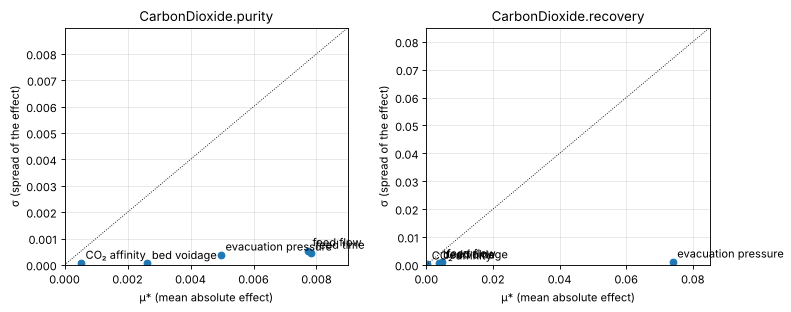

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, out in zip(axes, study.outputs):
    d = t[t["output"] == out]
    ax.scatter(d["mu_star"], d["sigma"])
    for _, r in d.iterrows():
        ax.annotate(r["input"], (r["mu_star"], r["sigma"]), textcoords="offset points", xytext=(4, 4))
    lim = max(d["mu_star"].max(), d["sigma"].max()) * 1.15
    ax.plot([0, lim], [0, lim], "k:", lw=0.8)
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="μ* (mean absolute effect)", ylabel="σ (spread of the effect)",
           title=out)
    ax.grid(alpha=0.3)
plt.tight_layout()

Inputs below the dotted line act mostly on their own. Keep the inputs whose μ\* reaches 10 % of the largest, for either KPI:

In [6]:
keep = screen.important(threshold=0.1)
[labels[p] for p in keep]

['feed time', 'feed flow', 'evacuation pressure', 'bed voidage']

## 2. Error bars

Latin hypercube Monte Carlo over the kept inputs: 100 runs, then 50 more at a time until every percentile is known to within 10 % of the 5–95 % band (at most 300 runs here).

In [7]:
spread = study.propagate(runs=100, batch=50, max_runs=300, inputs=keep)
print(spread, *spread.warnings, sep="\n")
spread.table(nominal=True).round(4)

<Propagation 4 inputs, 200 runs (converged), 0 failed>


,output,nominal,mean,sd,p05,p50,p95,p05_low,p05_high,p95_low,p95_high,min,max,valid,missing,converged,r2
0,CarbonDioxide.purity,0.9894,0.9891,0.0038,0.9827,0.9899,0.995,0.9823,0.9836,0.9939,0.9956,0.9787,0.9971,200,0,True,0.9789
1,CarbonDioxide.recovery,0.6828,0.6826,0.0215,0.6510,0.6817,0.715,0.6467,0.6525,0.7133,0.7183,0.6430,0.7212,200,0,True,0.9980


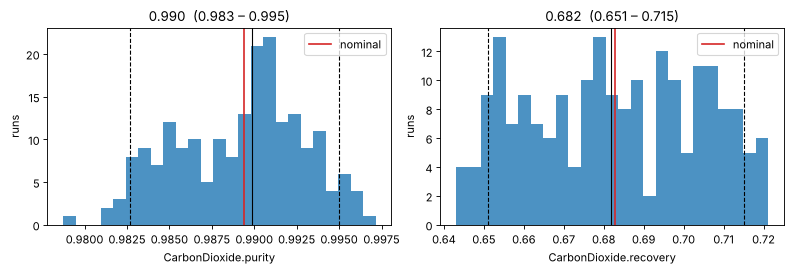

In [8]:
samples = spread.samples_table()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, out in zip(axes, study.outputs):
    v = samples.loc[samples["accepted"], out]
    p05, p50, p95 = spread.error_bars()[out]
    ax.hist(v, bins=25, alpha=0.8)
    for x, ls in ((p05, "--"), (p50, "-"), (p95, "--")):
        ax.axvline(x, color="k", ls=ls, lw=1)
    ax.axvline(nominal["outputs"][out], color="C3", lw=1.5, label="nominal")
    ax.set(xlabel=out, ylabel="runs", title=f"{p50:.3f}  ({p05:.3f} – {p95:.3f})")
    ax.legend()
plt.tight_layout()

Each input's share of each KPI's spread, from a regression on ranks. The shares add up to R²; an R² near 1 means they account for the whole spread.

In [9]:
sh = spread.shares()
sh["input"] = sh["input"].map(labels)
sh.pivot(index="input", columns="output", values="share").round(3)

output,CarbonDioxide.purity,CarbonDioxide.recovery
input,,
bed voidage,0.039,0.002
evacuation pressure,0.134,0.990
feed flow,0.352,0.004
feed time,0.341,0.003


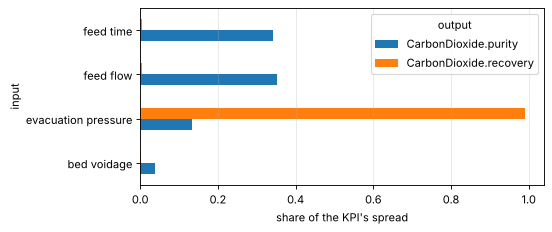

In [10]:
ax = sh.pivot(index="input", columns="output", values="share").plot.barh(figsize=(7, 3))
ax.set_xlabel("share of the KPI's spread")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()

The ranges decide the answer: these error bars describe what ±10 % on the operating values, the voidage range and a 5 % uncertainty in the CO₂ affinity do to the KPIs, nothing more. They do not include model error; see the [validation](https://samaffleck.github.io/skarstrom/validation/) for that. `spread.save("study.json")` keeps the study, every run and the results together.